# Workplace Diversity Analysis

## Goal

Analyze employee and organizational data to understand the company hierarchy, identify the main factors affecting salary, and evaluate whether employees are being treated fairly.

## Objectives

1. Identify each employee's organizational level: IC, MM, Director, VP, Executive, or CEO.
2. Calculate how many employees each person manages, including indirect reports.
3. Build a machine learning model to predict employee salary.
4. Identify the main salary drivers and investigate potential fairness concerns.

In [151]:
import pandas as pd
import numpy as np
company=pd.read_csv('company_hierarchy.csv')
employee=pd.read_csv('employee.csv')

In [152]:
print('company shape:',company.shape)
print('employee shape:',employee.shape)

company shape: (10000, 3)
employee shape: (10000, 6)


In [153]:
print(company.head())

   employee_id   boss_id   dept
0        46456  175361.0  sales
1       104708   29733.0     HR
2       120853   41991.0  sales
3       142630  171266.0     HR
4        72711  198240.0  sales


In [154]:
print(employee.head())

   employee_id  signing_bonus    salary degree_level sex  yrs_experience
0       138719              0  273000.0       Master   M               2
1         3192              0  301000.0     Bachelor   F               1
2       114657              0  261000.0       Master   F               2
3        29039              0   86000.0  High_School   F               4
4       118607              0  126000.0     Bachelor   F               3


In [155]:
print(company.info())
print(employee.info())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   employee_id  10000 non-null  int64  
 1   boss_id      9999 non-null   float64
 2   dept         10000 non-null  str    
dtypes: float64(1), int64(1), str(1)
memory usage: 234.5 KB
None
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   employee_id     10000 non-null  int64  
 1   signing_bonus   10000 non-null  int64  
 2   salary          10000 non-null  float64
 3   degree_level    10000 non-null  str    
 4   sex             10000 non-null  str    
 5   yrs_experience  10000 non-null  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 468.9 KB
None


In [156]:
print("Company missing values:")
print(company.isnull().sum())

print("\nEmployee missing values:")
print(employee.isnull().sum())

Company missing values:
employee_id    0
boss_id        1
dept           0
dtype: int64

Employee missing values:
employee_id       0
signing_bonus     0
salary            0
degree_level      0
sex               0
yrs_experience    0
dtype: int64


In [157]:
print('Company Duplicates:', company.duplicated().sum())
print('Employee Duplicates:', employee.duplicated().sum())

Company Duplicates: 0
Employee Duplicates: 0


In [158]:
print("Unique employee IDs in company:", company['employee_id'].nunique())
print("Unique employee IDs in employee:", employee['employee_id'].nunique())
print("Total employee IDs in company:", company['employee_id'].count())
print("Total employee IDs in employee:", employee['employee_id'].count())

Unique employee IDs in company: 10000
Unique employee IDs in employee: 10000
Total employee IDs in company: 10000
Total employee IDs in employee: 10000


In [159]:
ceo = company[company['boss_id'].isnull()]
print(ceo)

      employee_id  boss_id dept
2427        61554      NaN  CEO


In [160]:
executives = company[company['boss_id'] == 61554]
print(executives)

      employee_id  boss_id         dept
1009       110464  61554.0    marketing
1310        11277  61554.0        sales
2778        51535  61554.0  engineering
9640        93708  61554.0           HR


In [161]:
company['level'] = 'IC'
print(company)

      employee_id   boss_id         dept level
0           46456  175361.0        sales    IC
1          104708   29733.0           HR    IC
2          120853   41991.0        sales    IC
3          142630  171266.0           HR    IC
4           72711  198240.0        sales    IC
...           ...       ...          ...   ...
9995        45022  154703.0  engineering    IC
9996       173414  171461.0           HR    IC
9997       194688  161727.0  engineering    IC
9998        11698   75242.0  engineering    IC
9999       144338   55972.0           HR    IC

[10000 rows x 4 columns]


In [162]:
company.loc[company['boss_id']==61554, 'level'] = 'E'
print(company)

      employee_id   boss_id         dept level
0           46456  175361.0        sales    IC
1          104708   29733.0           HR    IC
2          120853   41991.0        sales    IC
3          142630  171266.0           HR    IC
4           72711  198240.0        sales    IC
...           ...       ...          ...   ...
9995        45022  154703.0  engineering    IC
9996       173414  171461.0           HR    IC
9997       194688  161727.0  engineering    IC
9998        11698   75242.0  engineering    IC
9999       144338   55972.0           HR    IC

[10000 rows x 4 columns]


In [163]:
company.loc[company['boss_id'].isnull(), 'level'] = 'CEO'
print(company)

      employee_id   boss_id         dept level
0           46456  175361.0        sales    IC
1          104708   29733.0           HR    IC
2          120853   41991.0        sales    IC
3          142630  171266.0           HR    IC
4           72711  198240.0        sales    IC
...           ...       ...          ...   ...
9995        45022  154703.0  engineering    IC
9996       173414  171461.0           HR    IC
9997       194688  161727.0  engineering    IC
9998        11698   75242.0  engineering    IC
9999       144338   55972.0           HR    IC

[10000 rows x 4 columns]


In [164]:
executive_ids = company.loc[company['level'] == 'E', 'employee_id']
print(executive_ids)

1009    110464
1310     11277
2778     51535
9640     93708
Name: employee_id, dtype: int64


In [165]:
company.loc[
    company['boss_id'].isin(executive_ids),
    'level'
] = 'VP'
print(company[company['level'] == 'VP'])


      employee_id   boss_id         dept level
52          79693   51535.0  engineering    VP
452         74062  110464.0    marketing    VP
673         97647  110464.0    marketing    VP
873        133795   51535.0  engineering    VP
1056        84011   11277.0        sales    VP
1112        40920  110464.0    marketing    VP
1231       162476   51535.0  engineering    VP
1251       152500   93708.0           HR    VP
2040        96752   11277.0        sales    VP
2218       107658  110464.0    marketing    VP
2464        71889   93708.0           HR    VP
2525        26053   93708.0           HR    VP
2954       176424  110464.0    marketing    VP
2999       190801   51535.0  engineering    VP
3038       109804   51535.0  engineering    VP
3152        36075   11277.0        sales    VP
3289       109308  110464.0    marketing    VP
3665       107152   51535.0  engineering    VP
3751       139032   11277.0        sales    VP
4230       124994   93708.0           HR    VP
4310       14

In [166]:
vp_ids = company.loc[company['level'] == 'VP', 'employee_id']
print(vp_ids)


52       79693
452      74062
673      97647
873     133795
1056     84011
1112     40920
1231    162476
1251    152500
2040     96752
2218    107658
2464     71889
2525     26053
2954    176424
2999    190801
3038    109804
3152     36075
3289    109308
3665    107152
3751    139032
4230    124994
4310    149778
6107     34280
6364     55537
6792    176367
6852    138045
7259    197876
8995     34051
9237    125855
9316     56068
9367     71499
9389    185673
9432     69728
9610    154041
9815    177860
9845    142146
Name: employee_id, dtype: int64


In [167]:
company.loc[company['boss_id'].isin(vp_ids), 'level'] = 'D'
print(company[company['level'] == 'D'])

      employee_id   boss_id         dept level
82         157492   34280.0        sales     D
176        131950   96752.0        sales     D
257         65522   34051.0        sales     D
266         89002   34280.0        sales     D
269        139507   97647.0    marketing     D
...           ...       ...          ...   ...
9707       113589  190801.0  engineering     D
9758        59566  125855.0           HR     D
9789       140317  107152.0  engineering     D
9797       181201  139032.0        sales     D
9846       198366  142146.0        sales     D

[160 rows x 4 columns]


In [168]:
print(company['level'].value_counts())

level
IC     9800
D       160
VP       35
E         4
CEO       1
Name: count, dtype: int64


In [169]:
D_ids = company.loc[company['level'] == 'D', 'employee_id']
print(D_ids)

82      157492
176     131950
257      65522
266      89002
269     139507
         ...  
9707    113589
9758     59566
9789    140317
9797    181201
9846    198366
Name: employee_id, Length: 160, dtype: int64


In [170]:
company.loc[company['boss_id'].isin(D_ids), 'level'] = 'MM'
print(company[company['level'] == 'MM'])

      employee_id   boss_id         dept level
3          142630  171266.0           HR    MM
12          51293  172989.0        sales    MM
15         159906   65174.0        sales    MM
19         169231  164851.0        sales    MM
35         175548  116660.0           HR    MM
...           ...       ...          ...   ...
9934       150408   61403.0  engineering    MM
9942        27393  198366.0        sales    MM
9969       105395   17837.0  engineering    MM
9982       109254  191418.0        sales    MM
9984        96664  125912.0    marketing    MM

[800 rows x 4 columns]


In [171]:
print(company['level'].value_counts())

level
IC     9000
MM      800
D       160
VP       35
E         4
CEO       1
Name: count, dtype: int64


## 3. Calculate Total Employee Reports

The goal is to calculate the total number of employees managed by each person, including both direct and indirect reports.

We start from the bottom of the hierarchy (IC) and work upward to the CEO.

Initially, every employee is assigned zero reports. We then update the counts based on the reporting hierarchy.

In [172]:
company['num_reports'] = 0

print(company.head())

   employee_id   boss_id   dept level  num_reports
0        46456  175361.0  sales    IC            0
1       104708   29733.0     HR    IC            0
2       120853   41991.0  sales    IC            0
3       142630  171266.0     HR    MM            0
4        72711  198240.0  sales    IC            0


In [173]:
print(company['level'].value_counts())

level
IC     9000
MM      800
D       160
VP       35
E         4
CEO       1
Name: count, dtype: int64


In [174]:
MM_reports = (
    company[company['level'] == 'IC']
    .groupby('boss_id')['employee_id']
    .count()
    .reset_index(name='direct_reports')
)

print(MM_reports.head())

   boss_id  direct_reports
0     79.0               9
1     90.0               8
2    252.0              10
3    742.0              17
4    754.0              16


In [175]:
company['num_reports'] = 0

In [176]:
company['num_reports'] = (
    company['employee_id']
    .map(MM_reports.set_index('boss_id')['direct_reports'])
    .fillna(0)
    .astype(int)
)
print(company.head())

print(company[company['level'] == 'MM'].head())

   employee_id   boss_id   dept level  num_reports
0        46456  175361.0  sales    IC            0
1       104708   29733.0     HR    IC            0
2       120853   41991.0  sales    IC            0
3       142630  171266.0     HR    MM           16
4        72711  198240.0  sales    IC            0
    employee_id   boss_id   dept level  num_reports
3        142630  171266.0     HR    MM           16
12        51293  172989.0  sales    MM           11
15       159906   65174.0  sales    MM           14
19       169231  164851.0  sales    MM           10
35       175548  116660.0     HR    MM           11


### Calculate Reports for Middle Managers

Counted the number of Individual Contributors (ICs) reporting directly to each Middle Manager.

Used `set_index()` and `map()` to match each manager's employee ID with their report count and update the `num_reports` column.

In [177]:
director_reports = (
    company[company['level'] == 'MM']
    .groupby('boss_id')
    .agg(
        direct_reports=('employee_id', 'count'),
        indirect_reports=('num_reports', 'sum')
    )
    .reset_index()
)

print(director_reports.head())

   boss_id  direct_reports  indirect_reports
0   2308.0               3                44
1   3235.0               7                77
2   3802.0               3                41
3   3917.0               7                80
4   5342.0               5                71


In [178]:
director_reports['total_reports'] = (
    director_reports['direct_reports']
    + director_reports['indirect_reports']
)

print(director_reports.head())

   boss_id  direct_reports  indirect_reports  total_reports
0   2308.0               3                44             47
1   3235.0               7                77             84
2   3802.0               3                41             44
3   3917.0               7                80             87
4   5342.0               5                71             76


In [179]:
company.loc[company['level'] == 'D', 'num_reports'] = (
    company.loc[company['level'] == 'D', 'employee_id']
    .map(director_reports.set_index('boss_id')['total_reports'])
)
print(company[company['level'] == 'D'].head())
print(company[company['level'] == 'MM'].head())

     employee_id  boss_id       dept level  num_reports
82        157492  34280.0      sales     D        114.0
176       131950  96752.0      sales     D         15.0
257        65522  34051.0      sales     D         41.0
266        89002  34280.0      sales     D         60.0
269       139507  97647.0  marketing     D         58.0
    employee_id   boss_id   dept level  num_reports
3        142630  171266.0     HR    MM         16.0
12        51293  172989.0  sales    MM         11.0
15       159906   65174.0  sales    MM         14.0
19       169231  164851.0  sales    MM         10.0
35       175548  116660.0     HR    MM         11.0


In [180]:
vp_reports= (
    company[company['level'] == 'D'].groupby('boss_id').agg(
        direct_reports=('employee_id', 'count'),
        indirect_reports=('num_reports', 'sum')
    )
    .reset_index()
)
print(vp_reports.head())

   boss_id  direct_reports  indirect_reports
0  26053.0               5             322.0
1  34051.0               8             599.0
2  34280.0               7             472.0
3  36075.0               4             187.0
4  40920.0               4             255.0


In [181]:
vp_reports['total_reports'] = (vp_reports['direct_reports'] + vp_reports['indirect_reports'])
print(vp_reports.head())

   boss_id  direct_reports  indirect_reports  total_reports
0  26053.0               5             322.0          327.0
1  34051.0               8             599.0          607.0
2  34280.0               7             472.0          479.0
3  36075.0               4             187.0          191.0
4  40920.0               4             255.0          259.0


In [182]:
company.loc[company['level'] == 'VP', 'num_reports'] = (
    company.loc[company['level'] == 'VP', 'employee_id']
    .map(vp_reports.set_index('boss_id')['total_reports'])
)
print(company[company['level'] == 'VP'].head())

      employee_id   boss_id         dept level  num_reports
52          79693   51535.0  engineering    VP        290.0
452         74062  110464.0    marketing    VP        308.0
673         97647  110464.0    marketing    VP        265.0
873        133795   51535.0  engineering    VP        179.0
1056        84011   11277.0        sales    VP        553.0


In [183]:
Executives_reports= (
    company[company['level']=='VP'].groupby('boss_id').agg(
    director_reports=('employee_id', 'count'),
    indirect_reports=('num_reports', 'sum')
).reset_index()
)
print(Executives_reports.head())

    boss_id  director_reports  indirect_reports
0   11277.0                10            3588.0
1   51535.0                10            2685.0
2   93708.0                 6            1687.0
3  110464.0                 9            2000.0


In [184]:
Executives_reports['total_reports'] = (Executives_reports['director_reports'] + Executives_reports['indirect_reports'])
print(Executives_reports.head())

    boss_id  director_reports  indirect_reports  total_reports
0   11277.0                10            3588.0         3598.0
1   51535.0                10            2685.0         2695.0
2   93708.0                 6            1687.0         1693.0
3  110464.0                 9            2000.0         2009.0


In [185]:
company.loc[company['level'] == 'E', 'num_reports'] = (
    company.loc[company['level'] == 'E', 'employee_id']
    .map(Executives_reports.set_index('boss_id')['total_reports'])
)
print(company[company['level'] == 'E'].head())

      employee_id  boss_id         dept level  num_reports
1009       110464  61554.0    marketing     E       2009.0
1310        11277  61554.0        sales     E       3598.0
2778        51535  61554.0  engineering     E       2695.0
9640        93708  61554.0           HR     E       1693.0


In [186]:
ceo_reports =(company[company['level']=='E'].groupby('boss_id').agg(
    director_reports=('employee_id', 'count'),
    indirect_reports=('num_reports', 'sum')
)).reset_index()
ceo_reports['total_reports'] = (ceo_reports['director_reports'] + ceo_reports['indirect_reports'])
print(ceo_reports.head())

   boss_id  director_reports  indirect_reports  total_reports
0  61554.0                 4            9995.0         9999.0


In [187]:
company.loc[company['level'] == 'CEO', 'num_reports'] = (
    company.loc[company['level'] == 'CEO', 'employee_id']
    .map(ceo_reports.set_index('boss_id')['total_reports'])
)
print(company[company['level'] == 'CEO'].head())

      employee_id  boss_id dept level  num_reports
2427        61554      NaN  CEO   CEO       9999.0


## Merge the two datasets

In [188]:
data=pd.merge(company,employee , on='employee_id',how='inner')
print(data.head())
print(data.info())
print(data.shape)

   employee_id   boss_id   dept level  num_reports  signing_bonus    salary  \
0        46456  175361.0  sales    IC          0.0              0  213000.0   
1       104708   29733.0     HR    IC          0.0              0   79000.0   
2       120853   41991.0  sales    IC          0.0              0  199000.0   
3       142630  171266.0     HR    MM         16.0              0  143000.0   
4        72711  198240.0  sales    IC          0.0              0  235000.0   

  degree_level sex  yrs_experience  
0     Bachelor   M               5  
1     Bachelor   F               3  
2  High_School   M               5  
3          PhD   F              13  
4       Master   M               1  
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   employee_id     10000 non-null  int64  
 1   boss_id         9999 non-null   float64
 2   dept            10000

In [189]:
print(data[data['num_reports'].isna()])

      employee_id  boss_id dept level  num_reports  signing_bonus   salary  \
7690         8473  26053.0   HR     D          NaN              0  60000.0   

     degree_level sex  yrs_experience  
7690     Bachelor   M              23  


In [190]:
print(
    company[company['boss_id'] == 8473]
)
print(company[company['employee_id'] == 8473])

company.loc[
    company['employee_id'] == 8473,
    'num_reports'
] = 0
print(company[company['employee_id'] == 8473])

Empty DataFrame
Columns: [employee_id, boss_id, dept, level, num_reports]
Index: []
      employee_id  boss_id dept level  num_reports
7690         8473  26053.0   HR     D          NaN
      employee_id  boss_id dept level  num_reports
7690         8473  26053.0   HR     D          0.0


In [191]:
ml_data = data[data['level'] != 'CEO'].drop(
    columns=['employee_id', 'boss_id']
).copy()
print(ml_data.info())
print(data['level'].value_counts())
print(ml_data['level'].value_counts())

<class 'pandas.DataFrame'>
Index: 9999 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   dept            9999 non-null   str    
 1   level           9999 non-null   str    
 2   num_reports     9998 non-null   float64
 3   signing_bonus   9999 non-null   int64  
 4   salary          9999 non-null   float64
 5   degree_level    9999 non-null   str    
 6   sex             9999 non-null   str    
 7   yrs_experience  9999 non-null   int64  
dtypes: float64(2), int64(2), str(4)
memory usage: 703.1 KB
None
level
IC     9000
MM      800
D       160
VP       35
E         4
CEO       1
Name: count, dtype: int64
level
IC    9000
MM     800
D      160
VP      35
E        4
Name: count, dtype: int64


In [192]:
degree_mapping = {
    'High_School': 1,
    'Bachelor': 2,
    'Master': 3,
    'PhD': 4
}
ml_data['degree_level'] = ml_data['degree_level'].map(degree_mapping)

print(ml_data[['degree_level']].head(10))

   degree_level
0             2
1             2
2             1
3             4
4             3
5             1
6             4
7             4
8             3
9             3


In [193]:
ml_data['level'] = data.loc[ml_data.index, 'level']
print(ml_data[['level']].head(10))

  level
0    IC
1    IC
2    IC
3    MM
4    IC
5    IC
6    IC
7    IC
8    IC
9    IC


In [194]:
level_mapping = {
    'IC': 1,
    'MM': 2,
    'D': 3,
    'VP': 4,
    'E': 5
}

ml_data['level'] = ml_data['level'].map(level_mapping)
print(ml_data[['level']].head(10))





   level
0      1
1      1
2      1
3      2
4      1
5      1
6      1
7      1
8      1
9      1


In [195]:
print(ml_data.head(10))

          dept  level  num_reports  signing_bonus    salary  degree_level sex  \
0        sales      1          0.0              0  213000.0             2   M   
1           HR      1          0.0              0   79000.0             2   F   
2        sales      1          0.0              0  199000.0             1   M   
3           HR      2         16.0              0  143000.0             4   F   
4        sales      1          0.0              0  235000.0             3   M   
5        sales      1          0.0              0  196000.0             1   M   
6           HR      1          0.0              0   99000.0             4   M   
7           HR      1          0.0              1   78000.0             4   M   
8  engineering      1          0.0              1  379000.0             3   M   
9        sales      1          0.0              0  249000.0             3   F   

   yrs_experience  
0               5  
1               3  
2               5  
3              13  
4       

In [196]:
print(ml_data[['level']].value_counts(dropna=False))

level
1        9000
2         800
3         160
4          35
5           4
Name: count, dtype: int64


In [197]:
ml_data['sex'] = data.loc[ml_data.index, 'sex']

print(ml_data['sex'].head(10))

0    M
1    F
2    M
3    F
4    M
5    M
6    M
7    M
8    M
9    F
Name: sex, dtype: str


In [198]:
sex_mapping = {
    'M': 1,
    'F': 0
    
}

ml_data['sex'] = ml_data['sex'].map(sex_mapping)


In [199]:
print(ml_data[['sex']].head(10))

   sex
0    1
1    0
2    1
3    0
4    1
5    1
6    1
7    1
8    1
9    0


In [200]:
print(ml_data['sex'].value_counts(dropna=False))

sex
1    6438
0    3561
Name: count, dtype: int64


In [201]:
ml_data=pd.get_dummies(ml_data, columns=['dept'],dtype=int)

In [202]:
print(ml_data.head(10))

   level  num_reports  signing_bonus    salary  degree_level  sex  \
0      1          0.0              0  213000.0             2    1   
1      1          0.0              0   79000.0             2    0   
2      1          0.0              0  199000.0             1    1   
3      2         16.0              0  143000.0             4    0   
4      1          0.0              0  235000.0             3    1   
5      1          0.0              0  196000.0             1    1   
6      1          0.0              0   99000.0             4    1   
7      1          0.0              1   78000.0             4    1   
8      1          0.0              1  379000.0             3    1   
9      1          0.0              0  249000.0             3    0   

   yrs_experience  dept_HR  dept_engineering  dept_marketing  dept_sales  
0               5        0                 0               0           1  
1               3        1                 0               0           0  
2              

In [203]:
X=ml_data.drop(columns=['salary'])
Y=ml_data['salary']
print("Features:", X.shape)
print("Target:", Y.shape)

Features: (9999, 10)
Target: (9999,)


### Train/Test Split
Before training Random Forest, we need to divide our data into two groups.

In [205]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (7999, 10)
X_test: (2000, 10)
y_train: (7999,)
y_test: (2000,)


In [206]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [207]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[252507.35525505 181102.67765908 199098.07070707 169038.0150696
 213182.49206349 225451.01389838 245943.66721508  86448.70146011
 205023.54363255 200471.64258128]


## Create the comparison DataFrame, 
then calculate MAE and R² to evaluate prediction accuracy.

In [208]:
comparison = pd.DataFrame({
    'Actual_Salary': y_test.to_numpy(),
    'Predicted_Salary': y_pred
})

print(comparison.head(10))

   Actual_Salary  Predicted_Salary
0       102000.0     252507.355255
1       261000.0     181102.677659
2       209000.0     199098.070707
3       172000.0     169038.015070
4       233000.0     213182.492063
5        74000.0     225451.013898
6       366000.0     245943.667215
7        81000.0      86448.701460
8       118000.0     205023.543633
9       219000.0     200471.642581


In [209]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("R-squared:", r2)

Mean Absolute Error: 59733.280804039074
R-squared: 0.29171317683778997


In [210]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

            Feature  Importance
6           dept_HR    0.582815
5    yrs_experience    0.105683
7  dept_engineering    0.104559
1       num_reports    0.070871
3      degree_level    0.053518
2     signing_bonus    0.028917
4               sex    0.025487
8    dept_marketing    0.009980
9        dept_sales    0.009495
0             level    0.008674


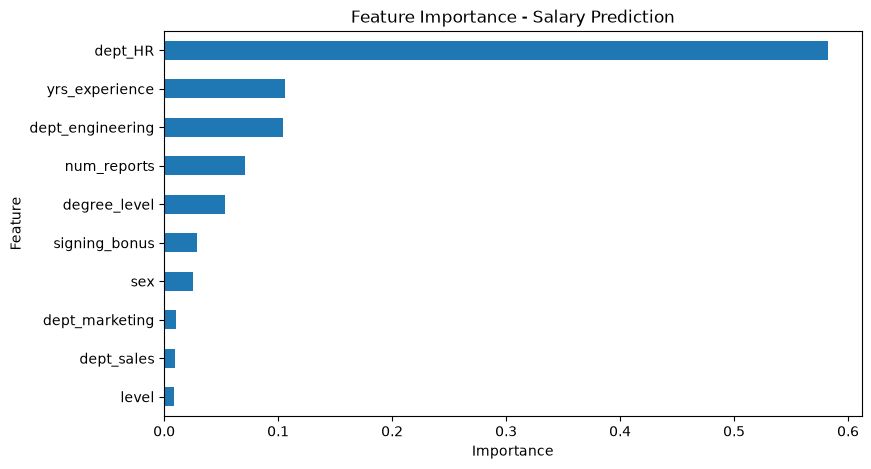

In [211]:
import matplotlib.pyplot as plt

feature_importance.plot(
    x='Feature',
    y='Importance',
    kind='barh',
    legend=False,
    figsize=(9, 5)
)

plt.gca().invert_yaxis()
plt.title('Feature Importance - Salary Prediction')
plt.xlabel('Importance')
plt.show()

## Feature Importance Analysis

We analyzed the importance of each feature in the trained Random Forest model.

Feature importance measures how much each variable contributed to reducing prediction error during the model's tree splits.

The goal is to identify which employee characteristics are most useful for predicting salary.

Feature importance does not establish causation or prove whether compensation is fair.

In [212]:
gender_salary = (
    data.groupby('sex')['salary']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

print(gender_salary)

     count       mean    median
sex                            
F     3561  171314.52  154000.0
M     6439  198954.34  194000.0


In [213]:
department_gender_salary = (
    data.groupby(['dept', 'sex'])['salary']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

print(department_gender_salary)

                 count       mean    median
dept        sex                            
CEO         M        1  700000.00  700000.0
HR          F     1058   84399.81   80000.0
            M      636   84827.04   79000.0
engineering F      671  246785.39  253000.0
            M     2025  242444.44  246000.0
marketing   F      651  192502.30  184000.0
            M     1359  195639.44  192000.0
sales       F     1181  194618.12  190000.0
            M     2418  194207.20  190000.0


In [214]:
gender_dept_comparison = (
    data[data['dept'] != 'CEO']
    .pivot_table(
        index='dept',
        columns='sex',
        values='salary',
        aggfunc='mean'
    )
)

gender_dept_comparison['Difference_M_minus_F'] = (
    gender_dept_comparison['M']
    - gender_dept_comparison['F']
)

print(gender_dept_comparison.round(2))

sex                  F          M  Difference_M_minus_F
dept                                                   
HR            84399.81   84827.04                427.23
engineering  246785.39  242444.44              -4340.95
marketing    192502.30  195639.44               3137.14
sales        194618.12  194207.20               -410.92


In [215]:
fairness_check = (
    data[data['level'] != 'CEO']
    .groupby(['dept', 'level', 'sex'])['salary']
    .agg(['count', 'mean'])
    .round(2)
)

print(fairness_check)

                       count       mean
dept        level sex                  
HR          D     F       10  124300.00
                  M       17  125764.71
            E     F        1  500000.00
            IC    F      972   82855.97
                  M      552   81382.25
            MM    F       74   92364.86
                  M       62   92080.65
            VP    F        1  181000.00
                  M        5  236000.00
engineering D     F        8  273000.00
                  M       35  255171.43
            E     M        1  650000.00
            IC    F      605  245971.90
                  M     1824  241908.44
            MM    F       56  252982.14
                  M      157  242382.17
            VP    F        2  214500.00
                  M        8  259250.00
marketing   D     F       15  233533.33
                  M       20  217000.00
            E     M        1  550000.00
            IC    F      588  191651.36
                  M     1214  193757.00


In [216]:
fairness_comparison = (
    data[data['level'] != 'CEO']
    .pivot_table(
        index=['dept', 'level'],
        columns='sex',
        values='salary',
        aggfunc='mean'
    )
)
fairness_comparison = fairness_comparison.reset_index()



print(fairness_comparison.round(2))

sex         dept level          F          M
0             HR     D  124300.00  125764.71
1             HR     E  500000.00        NaN
2             HR    IC   82855.97   81382.25
3             HR    MM   92364.86   92080.65
4             HR    VP  181000.00  236000.00
5    engineering     D  273000.00  255171.43
6    engineering     E        NaN  650000.00
7    engineering    IC  245971.90  241908.44
8    engineering    MM  252982.14  242382.17
9    engineering    VP  214500.00  259250.00
10     marketing     D  233533.33  217000.00
11     marketing     E        NaN  550000.00
12     marketing    IC  191651.36  193757.00
13     marketing    MM  191586.96  203957.26
14     marketing    VP  156000.00  271428.57
15         sales     D  206928.57  213146.34
16         sales     E        NaN  550000.00
17         sales    IC  192608.37  193872.81
18         sales    MM  210000.00  190290.00
19         sales    VP  353250.00  257000.00


In [217]:
fairness_comparison['Difference_M_minus_F'] = (
    fairness_comparison['M']
    - fairness_comparison['F']
)

print(fairness_comparison.round(2))

sex         dept level          F          M  Difference_M_minus_F
0             HR     D  124300.00  125764.71               1464.71
1             HR     E  500000.00        NaN                   NaN
2             HR    IC   82855.97   81382.25              -1473.72
3             HR    MM   92364.86   92080.65               -284.22
4             HR    VP  181000.00  236000.00              55000.00
5    engineering     D  273000.00  255171.43             -17828.57
6    engineering     E        NaN  650000.00                   NaN
7    engineering    IC  245971.90  241908.44              -4063.46
8    engineering    MM  252982.14  242382.17             -10599.98
9    engineering    VP  214500.00  259250.00              44750.00
10     marketing     D  233533.33  217000.00             -16533.33
11     marketing     E        NaN  550000.00                   NaN
12     marketing    IC  191651.36  193757.00               2105.64
13     marketing    MM  191586.96  203957.26              1237

## Final Findings and HR Recommendations

### 1. Organizational Structure

The analysis covered 10,000 employees across HR, Engineering, Marketing, and Sales, plus the CEO. Employee hierarchy levels were identified using reporting relationships, and direct and indirect report counts were calculated. The CEO has 9,999 total reports.

### 2. Salary Prediction Model

A Random Forest Regressor was trained using employee characteristics, including department, organizational level, experience, education, signing bonus, sex, and management responsibilities.

The model achieved:

- **Mean Absolute Error (MAE):** $59,730.60
- **R²:** 0.2917

These results indicate limited predictive accuracy. The model captures some salary patterns but leaves substantial variation unexplained.

### 3. Feature Importance

The most influential features in the trained Random Forest were:

- HR department indicator: 58.28%
- Years of experience: 10.57%
- Engineering department indicator: 10.46%
- Number of reports: 7.08%

These scores describe how the model used the features; they do not establish causal effects on salary.

### 4. Gender Salary Analysis

The overall average annual salary was approximately $198,954 for men and $171,315 for women, an unadjusted difference of $27,640 in favor of men.

However, department-level comparisons showed considerably smaller differences, suggesting that employee distribution across departments may explain part of the overall gap.

Comparisons within department and organizational level revealed additional variation, with some groups favoring men and others favoring women. These comparisons do not fully account for differences in experience, job duties, performance, or other relevant factors.

### 5. HR Recommendations

1. Review employee representation across departments and seniority levels to better understand the overall gender salary gap.
2. Investigate large salary differences within comparable job groups, prioritizing groups with sufficient employee counts.
3. Incorporate job title, location, tenure, performance, and other relevant compensation factors into future analysis.
4. Conduct a more rigorous adjusted pay-equity analysis before drawing conclusions about potential discrimination.
5. Improve salary prediction performance through additional data, model validation, and feature engineering.

### Conclusion

The project identified an overall gender salary difference and demonstrated that salary patterns vary substantially by department and organizational level. The findings provide a starting point for further HR investigation, but they do not establish whether compensation decisions are discriminatory or equitable.

The next business priority is a more detailed, adjusted compensation review supported by stronger employee-level data.